# MNIST Handwritten Digit Recognition: Deep Learning and CNN Training Pipeline

> **Project:** Handwritten Digit Recognition using the MNIST Dataset  
> **Framework:** TensorFlow / Keras  
> **Objective:** Compare a baseline ANN with multiple CNN architectures, evaluate the selected model on an untouched test set, and export the trained model and evaluation artifacts.

MNIST contains 70,000 grayscale images of handwritten digits 0–9: 60,000 training images and 10,000 test images. The ANN flattens each image to a vector; CNN layers learn local image features while retaining spatial structure.


In [ ]:
# ==============================================================================
# Cell 1: Environment Setup, Dependencies & Reproducibility Seeds
# ==============================================================================
import os
from pathlib import Path

working_directory = Path.cwd().resolve()
if not (working_directory / "ml" / "train_model.ipynb").is_file():
    if working_directory.name.lower() == "ml" and (working_directory / "train_model.ipynb").is_file():
        working_directory = working_directory.parent
    else:
        raise FileNotFoundError("Run this notebook from the project root or its ml folder.")
os.chdir(working_directory)

import json
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# Configure fixed random seeds for strict reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow Version : {tf.__version__}")
print(f"Keras Version      : {keras.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"GPU Available      : {len(gpus)} ({gpus[0].name if gpus else 'Running on CPU'})")

TensorFlow Version : 2.21.0
Keras Version      : 3.13.2
GPU Available      : 0 (Running on CPU)


---
## 📦 Step 1: Load the MNIST Dataset

We load MNIST directly through `keras.datasets.mnist.load_data()` and inspect its metadata.


In [ ]:
# ==============================================================================
# Cell 2: Load MNIST Dataset & Inspect Metadata
# ==============================================================================
(x_train_raw, y_train_raw), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

print("=" * 60)
print("MNIST Dataset Metadata & Shapes")
print("=" * 60)
print(f"Train Images Shape : {x_train_raw.shape}  | Data Type: {x_train_raw.dtype}")
print(f"Train Labels Shape : {y_train_raw.shape}        | Data Type: {y_train_raw.dtype}")
print(f"Test Images Shape  : {x_test_raw.shape}  | Data Type: {x_test_raw.dtype}")
print(f"Test Labels Shape  : {y_test.shape}        | Data Type: {y_test.dtype}")
print(f"Image Dimensions   : {x_train_raw.shape[1]} x {x_train_raw.shape[2]} pixels")
print(f"Unique Labels      : {np.unique(y_train_raw)} (Digits 0-9)")
print(f"Pixel Value Range  : Min = {x_train_raw.min()}, Max = {x_train_raw.max()}")
print("=" * 60)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST Dataset Metadata & Shapes
Train Images Shape : (60000, 28, 28)  | Data Type: uint8
Train Labels Shape : (60000,)        | Data Type: uint8
Test Images Shape  : (10000, 28, 28)  | Data Type: uint8
Test Labels Shape  : (10000,)        | Data Type: uint8
Image Dimensions   : 28 x 28 pixels
Unique Labels      : [0 1 2 3 4 5 6 7 8 9] (Digits 0-9)
Pixel Value Range  : Min = 0, Max = 255


---
## 🖼️ Step 2: Exploratory Data Analysis (EDA) & Sample Visualization

We display 25 sample handwritten digits in a 5×5 grid and verify the class balance across digits 0–9.



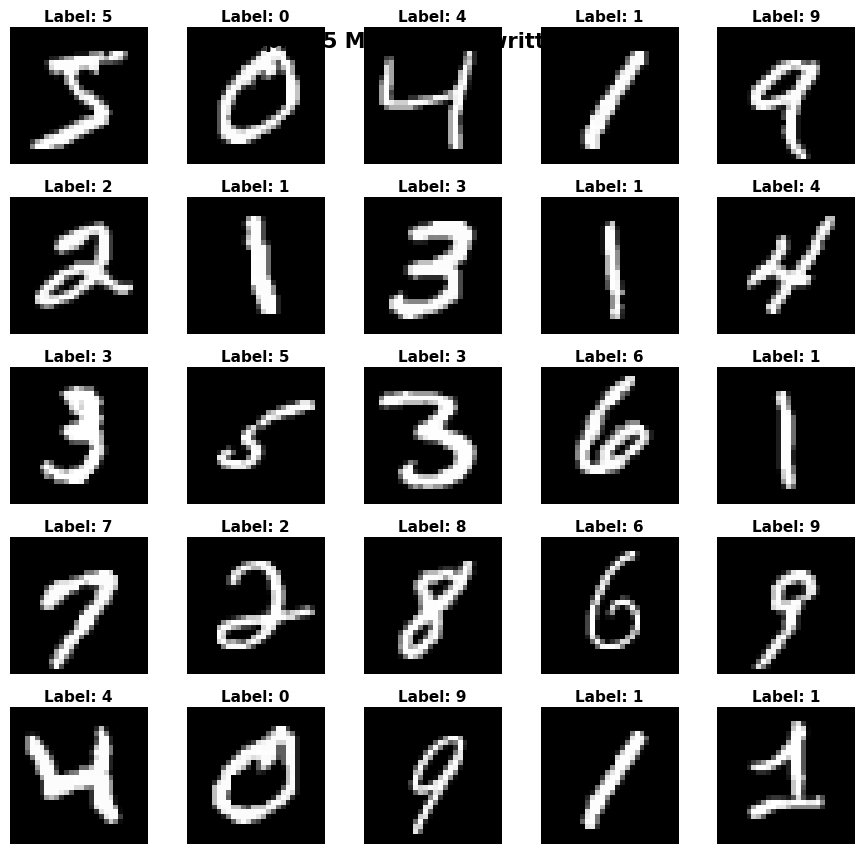

/tmp/ipykernel_1324/1432218933.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique, y=counts, palette='viridis')


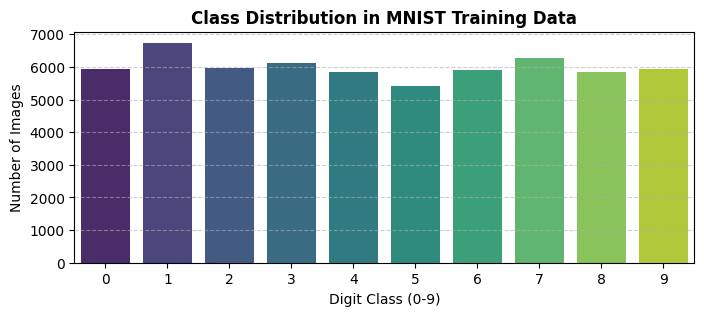

In [ ]:
# ==============================================================================
# Cell 3: Display 25 Sample Images (5x5 Grid) & Class Distribution
# ==============================================================================
plt.figure(figsize=(9, 9))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train_raw[i], cmap='gray')
    plt.title(f"Label: {y_train_raw[i]}", fontsize=11, fontweight='bold', pad=4)
    plt.axis('off')
plt.suptitle("Sample 25 MNIST Handwritten Digits", fontsize=15, fontweight='bold', y=0.92)
plt.tight_layout()
plt.show()

# Verify class balance
plt.figure(figsize=(8, 3))
unique, counts = np.unique(y_train_raw, return_counts=True)
sns.barplot(x=unique, y=counts, palette='viridis')
plt.title("Class Distribution in MNIST Training Data", fontsize=12, fontweight='bold')
plt.xlabel("Digit Class (0-9)")
plt.ylabel("Number of Images")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


---
## ⚙️ Step 3: Data Preprocessing & Validation Split

1. **Normalization:** Scale raw uint8 pixel values $[0, 255]$ to floating-point $[0.0, 1.0]$.
2. **Channel Reshaping:** CNNs require 4D inputs `(batch, height, width, channels)`. Grayscale channels = 1, so shape becomes `(28, 28, 1)`.
3. **Validation Split:** 10,000 images are reserved for validation monitoring and EarlyStopping. The test set remains untouched.



In [ ]:
# ==============================================================================
# Cell 4: Normalize Pixel Values, Reshape to (28, 28, 1), and Create Validation Split
# ==============================================================================
# 1. Normalize pixel values to 0.0 - 1.0
x_train_norm = x_train_raw.astype('float32') / 255.0
x_test_norm = x_test_raw.astype('float32') / 255.0

# 2. Reshape to add grayscale channel dimension (28, 28, 1)
x_train_all = np.expand_dims(x_train_norm, axis=-1)
x_test = np.expand_dims(x_test_norm, axis=-1)

# 3. Stratified validation split (50,000 train, 10,000 validation)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_all,
    y_train_raw,
    test_size=10000,
    random_state=SEED,
    stratify=y_train_raw
)

print(f"Training Set   : {x_train.shape}, Labels: {y_train.shape}")
print(f"Validation Set : {x_val.shape}, Labels: {y_val.shape}")
print(f"Test Set       : {x_test.shape}, Labels: {y_test.shape}")
print(f"Pixel Range    : [{x_train.min():.1f}, {x_train.max():.1f}]")


Training Set   : (50000, 28, 28, 1), Labels: (50000,)
Validation Set : (10000, 28, 28, 1), Labels: (10000,)
Test Set       : (10000, 28, 28, 1), Labels: (10000,)
Pixel Range    : [0.0, 1.0]


---
## 🏗️ Step 4: Baseline Model — Fully Connected Artificial Neural Network (ANN)

A Multilayer Perceptron (MLP) flattens 2D images into 784-dimensional vectors. It serves as our baseline benchmark.



In [ ]:
# ==============================================================================
# Cell 5: Build, Compile & Train Baseline ANN
# ==============================================================================
def build_baseline_ann():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1), name="ann_input"),
        layers.Flatten(name="flatten_layer"),
        layers.Dense(256, activation='relu', name="dense_1"),
        layers.Dropout(0.2, name="dropout_1"),
        layers.Dense(128, activation='relu', name="dense_2"),
        layers.Dropout(0.2, name="dropout_2"),
        layers.Dense(10, activation='softmax', name="output_classification")
    ], name="Baseline_ANN")
    return model

model_ann = build_baseline_ann()
model_ann.summary()

model_ann.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("\n--- Training Baseline ANN ---")
history_ann = model_ann.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)


Model: "Baseline_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_layer (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_classification (Dense)   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)


--- Training Baseline ANN ---
Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8915 - loss: 0.3716 - val_accuracy: 0.9520 - val_loss: 0.1627
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9539 - loss: 0.1536 - val_accuracy: 0.9657 - val_loss: 0.1138
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9661 - loss: 0.1126 - val_accuracy: 0.9704 - val_loss: 0.0956
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9732 - loss: 0.0871 - val_accuracy: 0.9742 - val_loss: 0.0874
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9771 - loss: 0.0732 - val_accuracy: 0.9751 - val_loss: 0.0841
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9805 - loss: 0.0612 - val_accuracy: 0.9777 - val_loss: 0.0815
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9824 - loss: 0.0543 - val_accuracy: 0.9762 - val_loss: 0.0837
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9849 - 

---
## 🚀 Step 5: CNN Configuration 1 — Standard Convolutional Network

**Architecture:**
* `Conv2D(32, 3x3)` + `MaxPooling2D(2x2)`
* `Conv2D(64, 3x3)` + `MaxPooling2D(2x2)`
* `Flatten()` -> `Dense(128, ReLU)` -> `Dropout(0.5)` -> `Dense(10, Softmax)`



In [ ]:
# ==============================================================================
# Cell 6: Build, Compile & Train CNN Configuration 1
# ==============================================================================
def build_cnn_config1():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1), name="cnn1_input"),
        layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same', name="conv1_32"),
        layers.MaxPooling2D(pool_size=(2, 2), name="pool1"),

        layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same', name="conv2_64"),
        layers.MaxPooling2D(pool_size=(2, 2), name="pool2"),

        layers.Flatten(name="flatten"),
        layers.Dense(128, activation='relu', name="dense_feature"),
        layers.Dropout(0.5, name="dropout"),
        layers.Dense(10, activation='softmax', name="output_classification")
    ], name="CNN_Config_1_Standard")
    return model

model_cnn1 = build_cnn_config1()
model_cnn1.summary()

model_cnn1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n--- Training CNN Configuration 1 ---")
history_cnn1 = model_cnn1.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)


Model: "CNN_Config_1_Standard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1_32 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_64 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_feature (Dense)           │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_classification (Dense)   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)


--- Training CNN Configuration 1 ---
Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 33s 83ms/step - accuracy: 0.9048 - loss: 0.3128 - val_accuracy: 0.9714 - val_loss: 0.0868
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 40s 80ms/step - accuracy: 0.9696 - loss: 0.1023 - val_accuracy: 0.9837 - val_loss: 0.0554
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 43s 84ms/step - accuracy: 0.9773 - loss: 0.0740 - val_accuracy: 0.9852 - val_loss: 0.0464
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 39s 80ms/step - accuracy: 0.9823 - loss: 0.0595 - val_accuracy: 0.9871 - val_loss: 0.0430
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 42s 82ms/step - accuracy: 0.9857 - loss: 0.0472 - val_accuracy: 0.9886 - val_loss: 0.0399
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 32s 81ms/step - accuracy: 0.9866 - loss: 0.0432 - val_accuracy: 0.9883 - val_loss: 0.0391
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 40s 79ms/step - accuracy: 0.9889 - loss: 0.0351 - val_accuracy: 0.9896 - val_loss: 0.0398
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 41s 80ms/ste

---
## 🛡️ Step 6: CNN Configuration 2 — Deep CNN with Batch Normalization

**Architecture:**
* Double convolution blocks with Batch Normalization and spatial Dropout.
* Block 1 extracts lower-level strokes; Block 2 extracts higher-level topological digit loops.



In [ ]:
# ==============================================================================
# Cell 7: Build, Compile & Train CNN Configuration 2 (Deep + BatchNorm)
# ==============================================================================
def build_cnn_config2():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1), name="cnn2_input"),

        # Block 1: 32 filters with Batch Normalization
        layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu', name="b1_conv1"),
        layers.BatchNormalization(name="b1_bn1"),
        layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu', name="b1_conv2"),
        layers.BatchNormalization(name="b1_bn2"),
        layers.MaxPooling2D(pool_size=(2, 2), name="b1_pool"),
        layers.Dropout(0.25, name="b1_drop"),

        # Block 2: 64 filters with Batch Normalization
        layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name="b2_conv1"),
        layers.BatchNormalization(name="b2_bn1"),
        layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name="b2_conv2"),
        layers.BatchNormalization(name="b2_bn2"),
        layers.MaxPooling2D(pool_size=(2, 2), name="b2_pool"),
        layers.Dropout(0.25, name="b2_drop"),

        # Dense Classifier Head
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation='relu', name="dense_1"),
        layers.BatchNormalization(name="dense_bn"),
        layers.Dropout(0.5, name="dense_drop"),
        layers.Dense(10, activation='softmax', name="output_classification")
    ], name="CNN_Config_2_Deep_BN")
    return model

model_cnn2 = build_cnn_config2()
model_cnn2.summary()

model_cnn2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n--- Training CNN Configuration 2 ---")
history_cnn2 = model_cnn2.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)


Model: "CNN_Config_2_Deep_BN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ b1_conv1 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn1 (BatchNormalization)     │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv2 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn2 (BatchNormalization)     │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_drop (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn1 (BatchNormalization)     │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv2 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn2 (BatchNormalization)     │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_drop (Dropout)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_bn (BatchNormalization)   │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_drop (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_classification (Dense)   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 469,098 (1.79 MB)

 Trainable params: 468,458 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)


--- Training CNN Configuration 2 ---
Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 138s 348ms/step - accuracy: 0.9359 - loss: 0.2145 - val_accuracy: 0.7442 - val_loss: 0.7396
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 144s 352ms/step - accuracy: 0.9790 - loss: 0.0701 - val_accuracy: 0.9878 - val_loss: 0.0397
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 136s 338ms/step - accuracy: 0.9842 - loss: 0.0510 - val_accuracy: 0.9883 - val_loss: 0.0365
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 137s 351ms/step - accuracy: 0.9876 - loss: 0.0412 - val_accuracy: 0.9897 - val_loss: 0.0331
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 133s 340ms/step - accuracy: 0.9894 - loss: 0.0346 - val_accuracy: 0.9915 - val_loss: 0.0272
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 1.


---
## 📊 Step 7: Model Comparison & Selection (Validation Performance)

We evaluate all candidates against the validation set, plot training curves, and select the winning architecture for final test evaluation.


Loading and preprocessing MNIST data...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

--- [Auto-Train] Training Baseline ANN ---
Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8909 - loss: 0.3655 - val_accuracy: 0.9537 - val_loss: 0.1505
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9544 - loss: 0.1512 - val_accuracy: 0.9669 - val_loss: 0.1150
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9674 - loss: 0.1084 - val_accuracy: 0.9710 - val_loss: 0.0959
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9741 - loss: 0.0851 - val_accuracy: 0.9721 - val_loss: 0.0912
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9770 - loss: 0.0722 - val_accuracy: 0.9759 - val_loss: 0.0816
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9817 - loss: 0.0577 - val_accuracy: 0.9753 - val_loss: 0.0858
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9834 - loss: 0.0523 - val_ac

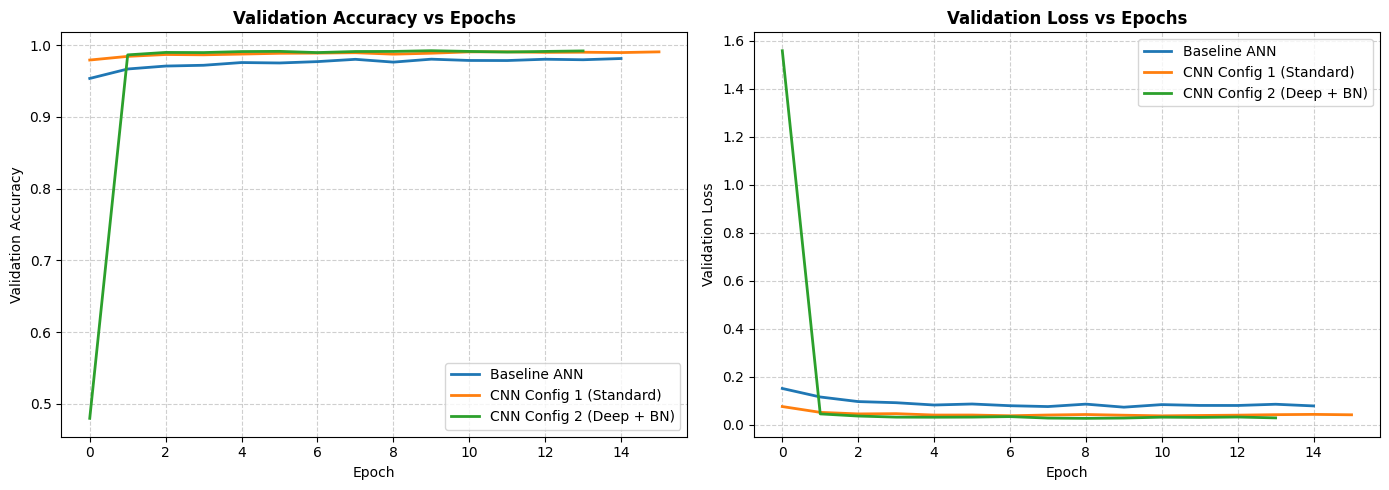

In [ ]:
# ==============================================================================
# Cell 8: Comparison Table & Training Curves Across Architectures (with Auto-Train fallback)
# ==============================================================================
import os
import numpy as np
import matplotlib.pyplot as plt
import keras

# Ensure data and early stopping callback exist
if 'x_train' not in globals():
    print("Loading and preprocessing MNIST data...")
    (x_train_raw, y_train_raw), (x_test_raw, y_test) = keras.datasets.mnist.load_data()
    x_train_norm = x_train_raw.astype('float32') / 255.0
    x_test_norm = x_test_raw.astype('float32') / 255.0
    x_train_all = np.expand_dims(x_train_norm, axis=-1)
    x_test = np.expand_dims(x_test_norm, axis=-1)
    from sklearn.model_selection import train_test_split
    x_train, x_val, y_train, y_val = train_test_split(
        x_train_all, y_train_raw, test_size=10000, random_state=42, stratify=y_train_raw
    )

if 'early_stop' not in globals():
    from tensorflow.keras import callbacks
    early_stop = callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
    )

# Fallback 1: Baseline ANN
if 'model_ann' not in globals() or 'history_ann' not in globals():
    print("\n--- [Auto-Train] Training Baseline ANN ---")
    if 'build_baseline_ann' not in globals():
        from tensorflow.keras import layers
        def build_baseline_ann():
            return keras.Sequential([
                layers.Input(shape=(28, 28, 1), name="ann_input"),
                layers.Flatten(name="flatten_layer"),
                layers.Dense(256, activation='relu', name="dense_1"),
                layers.Dropout(0.2, name="dropout_1"),
                layers.Dense(128, activation='relu', name="dense_2"),
                layers.Dropout(0.2, name="dropout_2"),
                layers.Dense(10, activation='softmax', name="output_classification")
            ], name="Baseline_ANN")
    model_ann = build_baseline_ann()
    model_ann.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    history_ann = model_ann.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=20, batch_size=128, callbacks=[early_stop], verbose=1)

# Fallback 2: CNN Config 1
if 'model_cnn1' not in globals() or 'history_cnn1' not in globals():
    print("\n--- [Auto-Train] Training CNN Configuration 1 ---")
    if 'build_cnn_config1' not in globals():
        from tensorflow.keras import layers
        def build_cnn_config1():
            return keras.Sequential([
                layers.Input(shape=(28, 28, 1), name="cnn1_input"),
                layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same', name="conv1_32"),
                layers.MaxPooling2D(pool_size=(2, 2), name="pool1"),
                layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same', name="conv2_64"),
                layers.MaxPooling2D(pool_size=(2, 2), name="pool2"),
                layers.Flatten(name="flatten"),
                layers.Dense(128, activation='relu', name="dense_feature"),
                layers.Dropout(0.5, name="dropout"),
                layers.Dense(10, activation='softmax', name="output_classification")
            ], name="CNN_Config_1_Standard")
    model_cnn1 = build_cnn_config1()
    model_cnn1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    history_cnn1 = model_cnn1.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=20, batch_size=128, callbacks=[early_stop], verbose=1)

# Fallback 3: CNN Config 2
if 'model_cnn2' not in globals() or 'history_cnn2' not in globals():
    print("\n--- [Auto-Train] Training CNN Configuration 2 ---")
    if 'build_cnn_config2' not in globals():
        from tensorflow.keras import layers
        def build_cnn_config2():
            return keras.Sequential([
                layers.Input(shape=(28, 28, 1), name="cnn2_input"),
                layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu', name="b1_conv1"),
                layers.BatchNormalization(name="b1_bn1"),
                layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu', name="b1_conv2"),
                layers.BatchNormalization(name="b1_bn2"),
                layers.MaxPooling2D(pool_size=(2, 2), name="b1_pool"),
                layers.Dropout(0.25, name="b1_drop"),
                layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name="b2_conv1"),
                layers.BatchNormalization(name="b2_bn1"),
                layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', name="b2_conv2"),
                layers.BatchNormalization(name="b2_bn2"),
                layers.MaxPooling2D(pool_size=(2, 2), name="b2_pool"),
                layers.Dropout(0.25, name="b2_drop"),
                layers.Flatten(name="flatten"),
                layers.Dense(128, activation='relu', name="dense_1"),
                layers.BatchNormalization(name="dense_bn"),
                layers.Dropout(0.5, name="dense_drop"),
                layers.Dense(10, activation='softmax', name="output_classification")
            ], name="CNN_Config_2_Deep_BN")
    model_cnn2 = build_cnn_config2()
    model_cnn2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    history_cnn2 = model_cnn2.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=20, batch_size=128, callbacks=[early_stop], verbose=1)

# Build the models dictionary and proceed
models_dict = {
    "Baseline ANN": (model_ann, history_ann),
    "CNN Config 1 (Standard)": (model_cnn1, history_cnn1),
    "CNN Config 2 (Deep + BN)": (model_cnn2, history_cnn2)
}

comparison_records = []
for name, (m, h) in models_dict.items():
    val_loss, val_acc = m.evaluate(x_val, y_val, verbose=0)
    best_epoch = int(np.argmin(h.history['val_loss']) + 1)
    train_acc = float(h.history['accuracy'][best_epoch - 1])
    comparison_records.append({
        "Model Name": name,
        "Train Acc (%)": round(train_acc * 100, 2),
        "Val Acc (%)": round(val_acc * 100, 2),
        "Val Loss": round(float(val_loss), 4),
        "Best Epoch": best_epoch,
        "Total Params": m.count_params()
    })

print("=" * 80)
print(f"{'Model Name':<28} | {'Train Acc':<10} | {'Val Acc':<10} | {'Val Loss':<10} | {'Params':<10}")
print("=" * 80)
for r in comparison_records:
    print(f"{r['Model Name']:<28} | {r['Train Acc (%)']:>8.2f}% | {r['Val Acc (%)']:>8.2f}% | {r['Val Loss']:>8.4f} | {r['Total Params']:>9,}")
print("=" * 80)

best_record = max(comparison_records, key=lambda x: x["Val Acc (%)"])
selected_model_name = best_record["Model Name"]
selected_model = models_dict[selected_model_name][0]
selected_history = models_dict[selected_model_name][1]
print(f"\n🏆 Selected Winning Model: '{selected_model_name}' (Val Accuracy: {best_record['Val Acc (%)']}%)")

# Plot validation curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for name, (_, h) in models_dict.items():
    plt.plot(h.history['val_accuracy'], label=f"{name}", linewidth=2)
plt.title("Validation Accuracy vs Epochs", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
for name, (_, h) in models_dict.items():
    plt.plot(h.history['val_loss'], label=f"{name}", linewidth=2)
plt.title("Validation Loss vs Epochs", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

os.makedirs("results", exist_ok=True)
plt.tight_layout()
plt.savefig("results/training_curves.png", dpi=200)
plt.show()

---
## 🎯 Step 8: Final Evaluation on Untouched Test Set

We evaluate the selected model on all 10,000 untouched test samples and compute:
* **Accuracy**
* **Macro Precision**
* **Macro Recall**
* **Macro F1-Score**


In [ ]:
# ==============================================================================
# Cell 9: Evaluate Winning Model on Test Set & Calculate Macro Metrics
# ==============================================================================
from sklearn.metrics import classification_report, precision_recall_fscore_support

# 1. Model inference on 10,000 test images
y_pred_probs = selected_model.predict(x_test, batch_size=256, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Test Loss & Accuracy
test_loss, test_acc = selected_model.evaluate(x_test, y_test, verbose=0)

# 3. Macro metrics
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')

print("\n" + "=" * 60)
print(f"FINAL UNTOUCHED TEST SET METRICS ({selected_model_name})")
print("=" * 60)
print(f"Test Accuracy   : {test_acc * 100:.2f}%")
print(f"Test Loss       : {test_loss:.4f}")
print(f"Macro Precision : {macro_p * 100:.2f}%")
print(f"Macro Recall    : {macro_r * 100:.2f}%")
print(f"Macro F1-Score  : {macro_f1 * 100:.2f}%")
print("=" * 60)

print("\nDetailed Per-Class Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 237ms/step

FINAL UNTOUCHED TEST SET METRICS (CNN Config 2 (Deep + BN))
Test Accuracy   : 99.36%
Test Loss       : 0.0184
Macro Precision : 99.36%
Macro Recall    : 99.35%
Macro F1-Score  : 99.36%

Detailed Per-Class Classification Report:
              precision    recall  f1-score   support

           0     0.9909    0.9990    0.9949       980
           1     0.9974    0.9965    0.9969      1135
           2     0.9990    0.9913    0.9951      1032
           3     0.9892    0.9980    0.9936      1010
           4     0.9899    0.9949    0.9924       982
           5     0.9944    0.9922    0.9933       892
           6     0.9979    0.9906    0.9942       958
           7     0.9875    0.9971    0.9923      1028
           8     0.9969    0.9887    0.9928       974
           9     0.9930    0.9871    0.9901      1009

    accuracy                         0.9936     10000
   macro avg     0.9936    0.9935    0.9936     10000
weighted avg     0.9936   

---
## 🔍 Step 9: Confusion Matrix & Prediction Error Analysis

We plot an annotated Seaborn Confusion Matrix and display examples of correct and misclassified predictions with confidence scores.

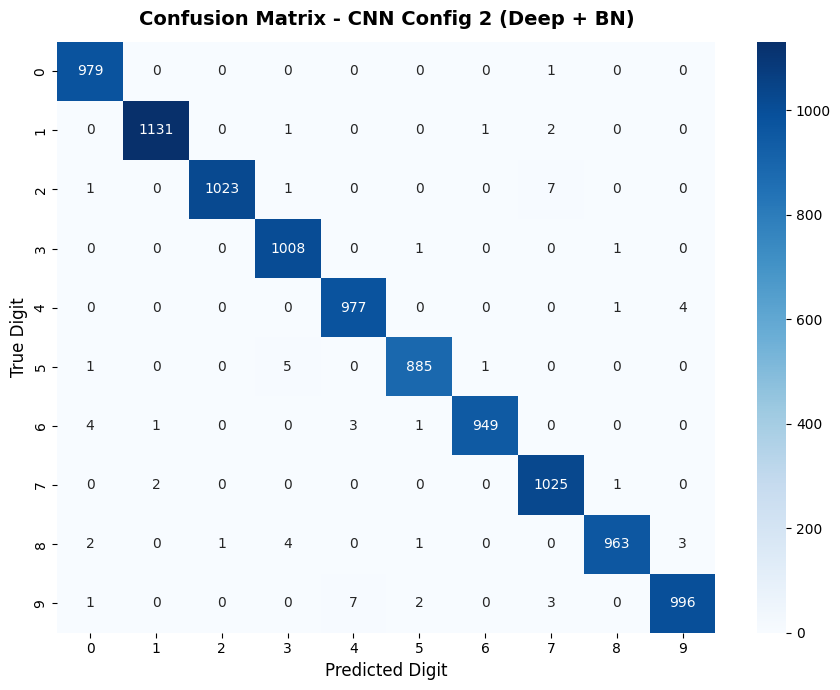

Total Test Samples  : 10000
Correct Predictions : 9936 (99.36%)
Misclassifications  : 64 (0.64%)


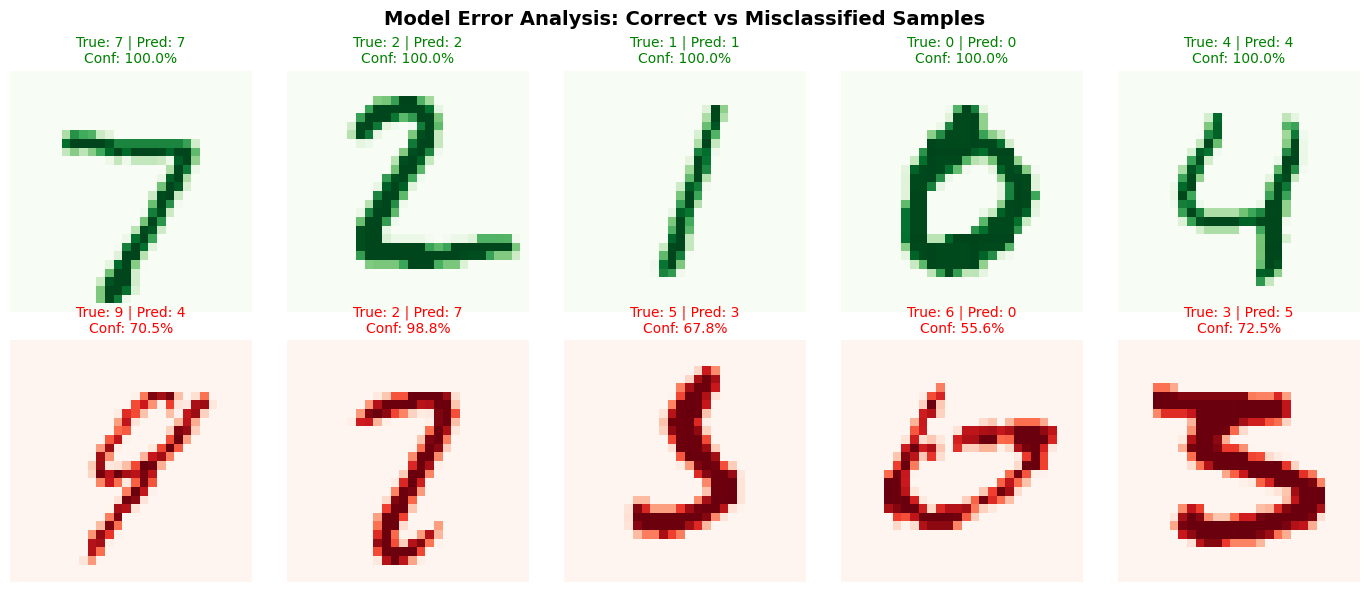

In [ ]:
# ==============================================================================
# Cell 10: Confusion Matrix Heatmap & Correct vs Incorrect Examples
# ==============================================================================
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=list(range(10)),
    yticklabels=list(range(10)),
    cbar=True
)
plt.title(f"Confusion Matrix - {selected_model_name}", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Predicted Digit", fontsize=12)
plt.ylabel("True Digit", fontsize=12)
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=200)
plt.show()

# Find correctly classified and misclassified indices
correct_idx = np.where(y_pred == y_test)[0]
incorrect_idx = np.where(y_pred != y_test)[0]

print(f"Total Test Samples  : {len(y_test)}")
print(f"Correct Predictions : {len(correct_idx)} ({len(correct_idx)/len(y_test)*100:.2f}%)")
print(f"Misclassifications  : {len(incorrect_idx)} ({len(incorrect_idx)/len(y_test)*100:.2f}%)")

# Plot 5 Correct & 5 Incorrect Examples
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

# Top Row: Correct Predictions
for i in range(5):
    idx = correct_idx[i]
    ax = axes[0, i]
    ax.imshow(x_test[idx].squeeze(), cmap='Greens')
    conf = y_pred_probs[idx][y_pred[idx]] * 100
    ax.set_title(f"True: {y_test[idx]} | Pred: {y_pred[idx]}\nConf: {conf:.1f}%", fontsize=10, color='green')
    ax.axis('off')

# Bottom Row: Incorrect Predictions
for i in range(5):
    idx = incorrect_idx[i]
    ax = axes[1, i]
    ax.imshow(x_test[idx].squeeze(), cmap='Reds')
    conf = y_pred_probs[idx][y_pred[idx]] * 100
    ax.set_title(f"True: {y_test[idx]} | Pred: {y_pred[idx]}\nConf: {conf:.1f}%", fontsize=10, color='red')
    ax.axis('off')

axes[0, 0].set_ylabel("CORRECT", fontsize=12, fontweight='bold', color='green')
axes[1, 0].set_ylabel("INCORRECT", fontsize=12, fontweight='bold', color='red')
plt.suptitle("Model Error Analysis: Correct vs Misclassified Samples", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("results/predictions_analysis.png", dpi=200)
plt.show()

---
## 💾 Step 10: Save Winning Model & Export Metrics JSON

We save the final selected model as `models/mnist_cnn.keras` and output all metrics to `results/metrics.json`.

In [ ]:
# ==============================================================================
# Cell 11: Save Model (.keras) & Export Metrics Summary JSON
# ==============================================================================
import os
import json
from sklearn.metrics import classification_report

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

# 1. Save trained model weights
model_save_path = "models/mnist_cnn.keras"
selected_model.save(model_save_path)
print(f"✅ Successfully saved model to: '{model_save_path}'")

# 2. Export quantitative metrics to results/metrics.json
report_dict = classification_report(y_test, y_pred, output_dict=True)

metrics_payload = {
    "selected_model": selected_model_name,
    "test_accuracy": round(float(test_acc), 4),
    "test_loss": round(float(test_loss), 4),
    "macro_precision": round(float(macro_p), 4),
    "macro_recall": round(float(macro_r), 4),
    "macro_f1_score": round(float(macro_f1), 4),
    "total_test_samples": int(len(y_test)),
    "confusion_matrix": cm.tolist(),
    "per_class_metrics": {
        str(digit): {
            "precision": round(report_dict[str(digit)]["precision"], 4),
            "recall": round(report_dict[str(digit)]["recall"], 4),
            "f1_score": round(report_dict[str(digit)]["f1-score"], 4),
            "support": int(report_dict[str(digit)]["support"])
        }
        for digit in range(10)
    }
}

metrics_json_path = "results/metrics.json"
with open(metrics_json_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)
print(f"✅ Successfully saved quantitative metrics to: '{metrics_json_path}'")

# Google Colab Download Helper (Uncomment if executing inside Google Colab):
# from google.colab import files
# files.download('models/mnist_cnn.keras')
# files.download('results/metrics.json')
# files.download('results/confusion_matrix.png')
# files.download('results/training_curves.png')
# files.download('results/predictions_analysis.png')

✅ Successfully saved model to: 'models/mnist_cnn.keras'
✅ Successfully saved quantitative metrics to: 'results/metrics.json'


In [ ]:
from pathlib import Path

# Get the project root directory
PROJECT_ROOT = Path.cwd()

# If running from the ml folder, move to the project root
if PROJECT_ROOT.name == "ml":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Create the models folder
model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model (using the correct variable 'selected_model')
model_path = model_dir / "mnist_cnn.keras"
selected_model.save(str(model_path))

print("Model saved successfully:", model_path)
print("File size:", model_path.stat().st_size, "bytes")

Model saved successfully: /content/models/mnist_cnn.keras
File size: 5708170 bytes


---
## College Viva: Key Concepts

- **CNN vs ANN:** Convolutions preserve local spatial relationships; flattening an image for a dense ANN does not.
- **Max pooling:** Downsamples feature maps while retaining prominent local activations.
- **ReLU and softmax:** ReLU is used in hidden feature layers; softmax produces the ten-class output distribution.
- **Sparse categorical cross-entropy:** Matches integer digit labels without one-hot encoding.
- **Early stopping:** Stops when validation loss ceases to improve and restores the best weights.
- **Macro metrics:** Average the per-digit metric equally, while weighted metrics account for each digit's support.


In [ ]:
from ml.export_evaluation import export_evaluation

export_evaluation(
    models_dict=models_dict,
    x_test=x_test,
    y_test=y_test,
    selected_model_name=selected_model_name,
    seed=SEED,
    batch_size=128,
    max_epochs=20,
    early_stopping_patience=5,
)
